### Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score)

### Data Loading & Exploration

In [2]:
df=pd.read_csv(r'data\Employers_data.csv')

In [3]:
df.head()

,Employee_ID,Name,Age,Gender,Department,Job_Title,Experience_Years,Education_Level,Location,Salary
0,1,Merle Ingram,24,Female,Engineering,Engineer,1,Master,Austin,90000
1,2,John Mayes,56,Male,Sales,Executive,33,Master,Seattle,195000
2,3,Carlos Wille,21,Male,Engineering,Intern,1,Bachelor,New York,35000
3,4,Michael Bryant,30,Male,Finance,Analyst,9,Bachelor,New York,75000
4,5,Paula Douglas,25,Female,HR,Analyst,2,Master,Seattle,70000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Employee_ID       10000 non-null  int64 
 1   Name              10000 non-null  object
 2   Age               10000 non-null  int64 
 3   Gender            10000 non-null  object
 4   Department        10000 non-null  object
 5   Job_Title         10000 non-null  object
 6   Experience_Years  10000 non-null  int64 
 7   Education_Level   10000 non-null  object
 8   Location          10000 non-null  object
 9   Salary            10000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 781.4+ KB


In [5]:
df.describe(include='all')

,Employee_ID,Name,Age,Gender,Department,Job_Title,Experience_Years,Education_Level,Location,Salary
count,10000.00000,10000,10000.000000,10000,10000,10000,10000.000000,10000,10000,10000.000000
unique,NaN,9868,NaN,2,6,5,NaN,3,5,NaN
top,NaN,James Smith,NaN,Male,Product,Manager,NaN,Master,Austin,NaN
freq,NaN,5,NaN,5108,1724,3325,NaN,4930,2034,NaN
mean,5000.50000,NaN,35.455900,NaN,NaN,NaN,12.370900,NaN,NaN,115381.500000
std,2886.89568,NaN,10.000213,NaN,NaN,NaN,9.148951,NaN,NaN,46066.139047
min,1.00000,NaN,21.000000,NaN,NaN,NaN,0.000000,NaN,NaN,25000.000000
25%,2500.75000,NaN,27.000000,NaN,NaN,NaN,5.000000,NaN,NaN,70000.000000
50%,5000.50000,NaN,34.000000,NaN,NaN,NaN,10.000000,NaN,NaN,120000.000000
75%,7500.25000,NaN,43.000000,NaN,NaN,NaN,19.000000,NaN,NaN,150000.000000


In [6]:
df.isna().sum()

Employee_ID         0
Name                0
Age                 0
Gender              0
Department          0
Job_Title           0
Experience_Years    0
Education_Level     0
Location            0
Salary              0
dtype: int64

In [7]:
X=df[['Experience_Years']]
y=df['Salary']

### Train/Test Split

In [8]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,shuffle=True,random_state=25)

### Model Training

In [9]:
model = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
y_pred=model.predict(X_test)

### Evaluation

In [11]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=model.score(X_test,y_test)
r2=r2_score(y_test,y_pred)
rmse=np.sqrt(mse)
weight=model.coef_[0]
bias=model.intercept_

In [12]:
print(f'Weight = {weight:.2f}')
print(f'Bias = {bias:.2f}')
print(f'MAE = {mae:.2f}')
print(f'MSE = {mse:.2f}')
print(f'RMSE = {rmse:.2f}')
print(f'Score: {score:.2f}')
print(f'R2 = {r2:.4f}')

Weight = 4524.48
Bias = 59351.14
MAE = 16245.46
MSE = 409553864.91
RMSE = 20237.44
Score: 0.80
R2 = 0.8023


Text(0, 0.5, 'Salary')

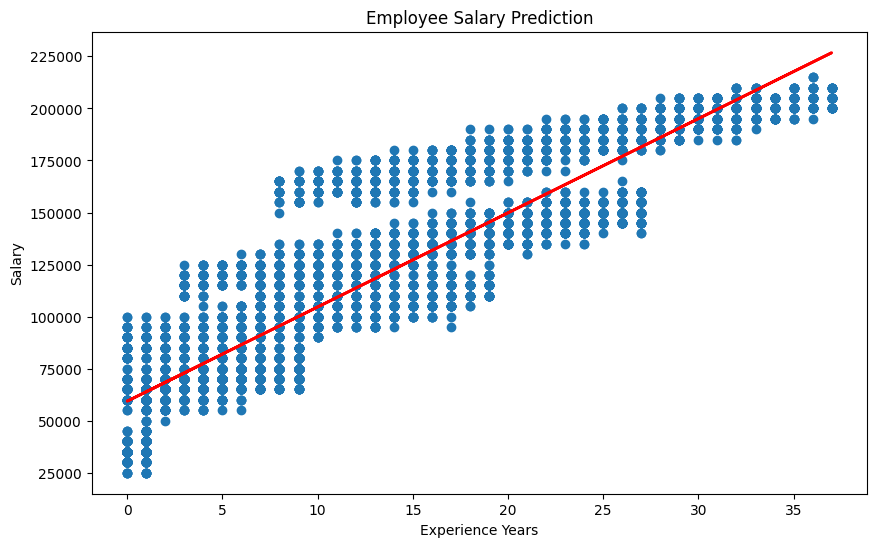

In [13]:
y_all=model.predict(X)

plt.figure(figsize=(10,6))
plt.scatter(X,y,label='Actual Salary')
plt.plot(X,y_all,color='red', linewidth=2,label='Regression Line')

plt.title('Employee Salary Prediction')
plt.xlabel('Experience Years')
plt.ylabel('Salary')